# OrdinalDR Supervised Simulation - DeepDRiD

Reproduces the **OrdinalDR paper** training pipeline on DeepDRiD.

> **Note**: Images nested as `Images/<patient_id>/<image_id>.jpg`. A custom `DeepDRDataset` handles this transparently.

| Feature | Details |
|---------|--------|
| Model | ResNet-50 (ImageNet pretrained) |
| Loss | Ordinal Encoding (configurable) |
| Optimizer | Adam lr=1e-4 wd=1e-4 |
| Resume | Auto-detects `last.ckpt` |

**Steps:** Setup -> Config -> Splits -> Data -> Train -> Evaluate -> Plots

## 1 . Setup

In [1]:
import os, sys, json, random, warnings
from pathlib import Path
import numpy as np
import pandas as pd
import torch
import matplotlib.pyplot as plt
from IPython.display import clear_output
from sklearn.metrics import (
    confusion_matrix, ConfusionMatrixDisplay,
    balanced_accuracy_score, cohen_kappa_score,
)
warnings.filterwarnings("ignore")

ROOT = Path.cwd()
for _ in range(6):
    if (ROOT / "OrdinalDRSimulation").exists():
        break
    ROOT = ROOT.parent
SIM_DIR = ROOT / "OrdinalDRSimulation"
sys.path.insert(0, str(ROOT))
sys.path.insert(0, str(SIM_DIR))
os.chdir(ROOT)

from OrdinalDRGrading.utils.data import load_dr_federated
from OrdinalDRGrading.utils.centralised_learning import (
    get_model, get_num_classes,
    train_one_epoch, validate,
    save_checkpoint, load_checkpoint,
)
from OrdinalDRGrading.utils.utils import get_criterion, log_message_to_file
from OrdinalDRGrading.utils.metrics import wilson_index, class_absolute_error

DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
print(f"Root   : {ROOT}")
print(f"Device : {DEVICE}")


Root   : d:\Research\Dr.Mohammad(LAB)\ordinal classify\MMRDR\Workspace
Device : cuda


## 2 . Configuration

In [8]:
SEED = 42


def seed_everything(s):
    random.seed(s); np.random.seed(s)
    torch.manual_seed(s); torch.cuda.manual_seed_all(s)
    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False


seed_everything(SEED)

CONFIG = {
    "train": {
        "num_classes":        5,
        "batch_size":         64,
        "num_workers":        0,
        "augmentations":      True,
        "epochs":             50,
        "lr":                 1e-3,
        "loss":               "exp_MSE",
        "model_name":         "resnet50",
        "pretrained":         True,
        "accumulation_steps": 8,
        "lamda":              0.5,
        "lamda_2":            0.0,
        "val_size":           0.2,
    }
}

LOSS_NAME   = CONFIG["train"]["loss"]
MODEL_NAME  = CONFIG["train"]["model_name"]
NUM_CLASSES = CONFIG["train"]["num_classes"]
RUN_NAME    = f"{MODEL_NAME}_{LOSS_NAME}_seed{SEED}"
FOLD        = "fold_0"
DATASET     = "DeepDRiD"

DEEPDR_ROOT   = Path(r"G:\Datasets\DR\DeepDR\DeepDRiD-master\regular_fundus_images")
TRAIN_IMG_DIR = DEEPDR_ROOT / "regular-fundus-training" / "Images"
VAL_IMG_DIR   = DEEPDR_ROOT / "regular-fundus-validation" / "Images"

SPLITS_DIR   = SIM_DIR / "OrdinalDRGrading" / "data" / "splits" / DATASET
TRAIN_CSV    = SPLITS_DIR / "train.csv"
VAL_CSV      = SPLITS_DIR / "val.csv"
RESULTS_DIR  = SIM_DIR / "results" / "EXPERIMENTS"
TRAIN_FOLDER = RESULTS_DIR / "centralised" / f"{DATASET}_{RUN_NAME}" / FOLD / "train"
CKPT_DIR     = TRAIN_FOLDER / "checkpoints"
LAST_CKPT    = CKPT_DIR / "last.ckpt"
BEST_CKPT    = CKPT_DIR / "best_wilson.ckpt"
LOG_FILE     = TRAIN_FOLDER / "train_log.txt"

SPLITS_DIR.mkdir(parents=True, exist_ok=True)
TRAIN_FOLDER.mkdir(parents=True, exist_ok=True)
CKPT_DIR.mkdir(parents=True, exist_ok=True)
(TRAIN_FOLDER / "plots").mkdir(exist_ok=True)

print(f"Dataset   : {DATASET}  |  Run: {RUN_NAME}")
print(f"Train imgs: {TRAIN_IMG_DIR}  (exists: {TRAIN_IMG_DIR.exists()})")
print(f"Val   imgs: {VAL_IMG_DIR}  (exists: {VAL_IMG_DIR.exists()})")
print(f"Loss: {LOSS_NAME}  |  Model: {MODEL_NAME}  |  Classes: {NUM_CLASSES}")


Dataset   : DeepDRiD  |  Run: resnet50_exp_MSE_seed42
Train imgs: G:\Datasets\DR\DeepDR\DeepDRiD-master\regular_fundus_images\regular-fundus-training\Images  (exists: True)
Val   imgs: G:\Datasets\DR\DeepDR\DeepDRiD-master\regular_fundus_images\regular-fundus-validation\Images  (exists: True)
Loss: exp_MSE  |  Model: resnet50  |  Classes: 5


## 2b . Generate Splits (run once)

In [9]:
# DeepDRiD CSV columns: patient_id, image_id, image_path, patient_DR_Level, ...
# Images nested as:  Images/<patient_id>/<image_id>.jpg
if not TRAIN_CSV.exists() or not VAL_CSV.exists():
    print("Generating splits from DeepDRiD CSVs ...")
    src_t = pd.read_csv(
        DEEPDR_ROOT / "regular-fundus-training" / "regular-fundus-training.csv"
    )
    src_v = pd.read_csv(
        DEEPDR_ROOT / "regular-fundus-validation" / "regular-fundus-validation.csv"
    )
    train_out = pd.DataFrame({
        "Filename": src_t["image_id"].astype(str) + ".jpg",
        "Label":    src_t["patient_DR_Level"].astype(int),
    })
    val_out = pd.DataFrame({
        "Filename": src_v["image_id"].astype(str) + ".jpg",
        "Label":    src_v["patient_DR_Level"].astype(int),
    })
    train_out.to_csv(TRAIN_CSV, index=False)
    val_out.to_csv(VAL_CSV, index=False)
    print(f"  {len(train_out)} train rows  /  {len(val_out)} val rows  written.")
else:
    print(f"Splits already exist: {TRAIN_CSV}")


Splits already exist: d:\Research\Dr.Mohammad(LAB)\ordinal classify\MMRDR\Workspace\OrdinalDRSimulation\OrdinalDRGrading\data\splits\DeepDRiD\train.csv


## 3 . Load Data

In [10]:
train_dfs = pd.read_csv(TRAIN_CSV)
val_dfs   = pd.read_csv(VAL_CSV)
print(f"Train: {len(train_dfs):,}   Val: {len(val_dfs):,}")
print("\nLabel distribution (train):")
print(train_dfs["Label"].value_counts().sort_index().to_frame("count").T)
print("\nLabel distribution (val):")
print(val_dfs["Label"].value_counts().sort_index().to_frame("count").T)

# Verify nested path (Images/<pid>/<image_id>.jpg)
import re
sample = train_dfs["Filename"].iloc[0]
pid = re.match(r"^(\d+)_", sample).group(1)
test_path = TRAIN_IMG_DIR / pid / sample
print(f"\nSample path: {test_path}")
print(f"  exists: {test_path.exists()}")


Train: 1,200   Val: 400

Label distribution (train):
Label    0    1    2    3    4
count  360  240  240  240  120

Label distribution (val):
Label    0   1   2   3   4
count  120  80  80  80  40

Sample path: G:\Datasets\DR\DeepDR\DeepDRiD-master\regular_fundus_images\regular-fundus-training\Images\1\1_l1.jpg
  exists: True


In [11]:
import re
from torch.utils.data import Dataset, DataLoader
from torchvision import transforms
from PIL import Image

_MEAN = (0.485, 0.456, 0.406)
_STD  = (0.229, 0.224, 0.225)


def get_transform(is_train: bool = True):
    if is_train:
        return transforms.Compose([
            transforms.Resize(256),
            transforms.RandomCrop(224),
            transforms.RandomHorizontalFlip(),
            transforms.RandomVerticalFlip(),
            transforms.ColorJitter(0.3, 0.3, 0.3, 0.1),
            transforms.ToTensor(),
            transforms.Normalize(_MEAN, _STD),
        ])
    return transforms.Compose([
        transforms.Resize(256),
        transforms.CenterCrop(224),
        transforms.ToTensor(),
        transforms.Normalize(_MEAN, _STD),
    ])


class DeepDRDataset(Dataset):
    """Handles the nested  Images/<patient_id>/<image_id>.jpg  path structure."""

    def __init__(self, df, images_root, transform):
        self.df        = df.reset_index(drop=True)
        self.root      = Path(images_root)
        self.transform = transform

    def __len__(self):
        return len(self.df)

    def __getitem__(self, idx):
        row = self.df.iloc[idx]
        fn  = str(row["Filename"])                     # e.g. "1_l1.jpg"
        pid = re.match(r"^(\d+)_", fn).group(1)      # patient folder "1"
        img = Image.open(self.root / pid / fn).convert("RGB")
        return self.transform(img), int(row["Label"])


def seed_worker(w):
    s = torch.initial_seed() % 2 ** 32
    np.random.seed(s); random.seed(s)


g = torch.Generator()
g.manual_seed(SEED)

train_dataset = DeepDRDataset(train_dfs, TRAIN_IMG_DIR, get_transform(True))
val_dataset   = DeepDRDataset(val_dfs,   VAL_IMG_DIR,   get_transform(False))

train_loader = DataLoader(
    train_dataset, batch_size=CONFIG["train"]["batch_size"],
    shuffle=True, num_workers=0,
    worker_init_fn=seed_worker, generator=g, drop_last=False,
)
val_loader = DataLoader(
    val_dataset, batch_size=CONFIG["train"]["batch_size"],
    shuffle=False, num_workers=0, drop_last=False,
)

print(f"Train batches: {len(train_loader)}  Val batches: {len(val_loader)}")
imgs, lbls = next(iter(train_loader))
print(f"Batch: {imgs.shape}  range=[{imgs.min():.2f}, {imgs.max():.2f}]")


Train batches: 19  Val batches: 7
Batch: torch.Size([64, 3, 224, 224])  range=[-2.12, 2.64]


## 4 . Build Model and Criterion

In [13]:
num_classes = get_num_classes(CONFIG)
model = get_model(MODEL_NAME, CONFIG["train"]["pretrained"], CONFIG).to(DEVICE)
criterion = get_criterion(
    LOSS_NAME, num_classes,
    CONFIG["train"]["lamda"], CONFIG["train"]["lamda_2"], DEVICE,
).to(DEVICE)
optimizer = torch.optim.Adam(
    model.parameters(), lr=CONFIG["train"]["lr"], weight_decay=1e-4
)
total_p = sum(p.numel() for p in model.parameters())
print(f"Model     : {MODEL_NAME}  {total_p / 1e6:.1f}M params")
print(f"Criterion : {criterion.__class__.__name__}")
print(f"Optimizer : Adam  lr={CONFIG['train']['lr']}")


This experiment uses the exp_MSE loss.
Model     : resnet50  23.5M params
Criterion : Expectation_based_MSE
Optimizer : Adam  lr=0.001


## 5 . Resumable Training Loop

Set `FORCE_RESTART = True` to start fresh.

In [14]:
FORCE_RESTART    = False
start_epoch      = 0
best_wilson_idx  = float("inf")
loss_history:     list = []
val_loss_history: list = []
wilson_history:   list = []

if LAST_CKPT.exists() and not FORCE_RESTART:
    print(f"[Resume] Found: {LAST_CKPT}")
    ckpt = load_checkpoint(LAST_CKPT, model, optimizer, DEVICE)
    start_epoch      = ckpt["epoch"] + 1
    best_wilson_idx  = ckpt["best_wilson_idx"]
    loss_history     = ckpt.get("loss_per_epoch", [])
    val_loss_history = ckpt.get("val_loss_per_epoch", [])
    wilson_history   = ckpt.get("wilson_per_epoch") or [float("nan")] * len(loss_history)
    print(f"[Resume] Epoch {start_epoch}  best Wilson: {best_wilson_idx:.4f}")
    log_message_to_file(LOG_FILE, f"\n[RESUME] epoch {start_epoch}\n")
else:
    print("[Fresh start] Training from scratch.")
    log_message_to_file(
        LOG_FILE,
        f"=== NEW RUN  {DATASET}  {MODEL_NAME}  {LOSS_NAME}  seed{SEED} ===\n",
    )


[Fresh start] Training from scratch.


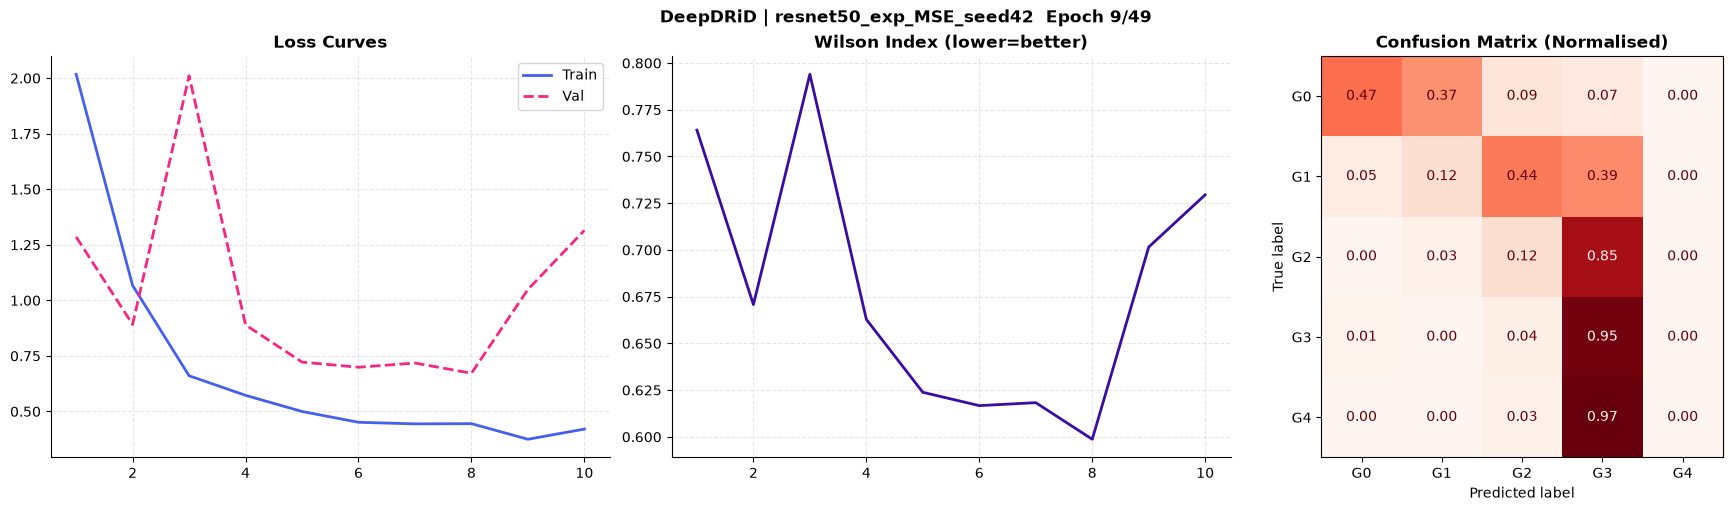

KeyboardInterrupt: 

In [15]:
EPOCHS      = CONFIG["train"]["epochs"]
ACCUM_STEPS = CONFIG["train"]["accumulation_steps"]
PLOT_EVERY  = 10


def draw_live_curves(loss_h, val_h, wilson_h, conf_mat, epoch):
    clear_output(wait=True)
    fig, axes = plt.subplots(1, 3, figsize=(18, 5), constrained_layout=True)
    # -- Loss
    axes[0].plot(range(1, len(loss_h) + 1), loss_h, label="Train", color="#4361EE", linewidth=2)
    axes[0].plot(range(1, len(val_h) + 1), val_h, label="Val", color="#F72585",
                 linewidth=2, linestyle="--")
    axes[0].set_title("Loss Curves", fontweight="bold")
    axes[0].legend(); axes[0].spines[["top", "right"]].set_visible(False)
    axes[0].grid(alpha=0.3, linestyle="--")
    # -- Wilson
    axes[1].plot(range(1, len(wilson_h) + 1), wilson_h, color="#3A0CA3", linewidth=2)
    axes[1].set_title("Wilson Index (lower=better)", fontweight="bold")
    axes[1].spines[["top", "right"]].set_visible(False)
    axes[1].grid(alpha=0.3, linestyle="--")
    # -- Confusion matrix
    if conf_mat is not None:
        row_sums = conf_mat.sum(axis=1)[:, np.newaxis]
        cm_n = np.divide(conf_mat.astype("float"), row_sums,
                         out=np.zeros_like(conf_mat, dtype=float), where=row_sums != 0)
        ConfusionMatrixDisplay(
            cm_n, display_labels=[f"G{i}" for i in range(NUM_CLASSES)]
        ).plot(ax=axes[2], cmap="Reds", colorbar=False, values_format=".2f")
        axes[2].set_title("Confusion Matrix (Normalised)", fontweight="bold")
    fig.suptitle(f"{DATASET} | {RUN_NAME}  Epoch {epoch}/{EPOCHS - 1}", fontweight="bold")
    plt.savefig(TRAIN_FOLDER / "plots" / "live_curves.png", dpi=80)
    plt.show()


print(f"Training: {start_epoch} -> {EPOCHS - 1}")

for epoch in range(start_epoch, EPOCHS):
    train_loss = train_one_epoch(
        model=model, dataloader=train_loader, device=DEVICE,
        criterion=criterion, optimizer=optimizer,
        accumulation_steps=ACCUM_STEPS, log_file_name=LOG_FILE, epoch=epoch,
    )
    loss_history.append(train_loss)

    val_loss, amae, wilson_idx, conf_mat = validate(
        model=model, dataloader=val_loader, device=DEVICE,
        criterion=criterion, epoch=epoch, log_file_name=LOG_FILE,
    )
    val_loss_history.append(val_loss)
    wilson_history.append(wilson_idx)

    if wilson_idx < best_wilson_idx:
        best_wilson_idx = wilson_idx
        torch.save(model.state_dict(), BEST_CKPT)
        print(f"  New best Wilson: {best_wilson_idx:.4f} -> {BEST_CKPT.name}")
        log_message_to_file(LOG_FILE, f"[BEST] Epoch {epoch} wilson={best_wilson_idx:.4f}")

    save_checkpoint(
        path=LAST_CKPT, epoch=epoch, model=model, optimizer=optimizer,
        best_wilson_idx=best_wilson_idx,
        loss_per_epoch=loss_history, val_loss_per_epoch=val_loss_history,
        config=CONFIG, wilson_per_epoch=wilson_history,
    )

    print(
        f"Epoch {epoch:>3}/{EPOCHS - 1}  train={train_loss:.4f}  val={val_loss:.4f}"
        f"  amae={amae:.4f}  wilson={wilson_idx:.4f}  best={best_wilson_idx:.4f}"
    )

    if (epoch + 1) % PLOT_EVERY == 0 or epoch == EPOCHS - 1:
        draw_live_curves(loss_history, val_loss_history, wilson_history, conf_mat, epoch)

print(f"Training complete!  Best Wilson: {best_wilson_idx:.4f}")
print(f"Best model : {BEST_CKPT}")


## 6 . Evaluation

In [ ]:
from tqdm.notebook import tqdm

if BEST_CKPT.exists():
    model.load_state_dict(torch.load(BEST_CKPT, map_location=DEVICE))
    print(f"Loaded: {BEST_CKPT}")

model.eval()
all_preds, all_labels = [], []
with torch.no_grad():
    for images, labels in tqdm(val_loader, desc="Evaluating"):
        preds = torch.argmax(model(images.to(DEVICE)), dim=1)
        all_preds.append(preds.cpu())
        all_labels.append(labels)

y_pred = torch.cat(all_preds).numpy()
y_true = torch.cat(all_labels).numpy()

wilson  = wilson_index(y_pred, y_true)
amae    = class_absolute_error(y_pred, y_true)
bal_acc = balanced_accuracy_score(y_true, y_pred)
kappa   = cohen_kappa_score(y_true, y_pred, weights="quadratic")

print("=" * 50)
print(f"  Dataset      : {DATASET}")
print(f"  QWK (Kappa)  : {kappa:.4f}")
print(f"  Wilson Index : {wilson:.4f}")
print(f"  AMAE         : {amae:.4f}")
print(f"  Balanced Acc : {bal_acc:.4f}")
print("=" * 50)

metrics_out = {
    "dataset": DATASET, "qwk": float(kappa), "wilson": float(wilson),
    "amae": float(amae), "bal_acc": float(bal_acc),
    "model": MODEL_NAME, "loss": LOSS_NAME, "seed": SEED,
}
with open(TRAIN_FOLDER / "val_metrics.json", "w") as f:
    json.dump(metrics_out, f, indent=4)
print(f"Saved -> {TRAIN_FOLDER}/val_metrics.json")


## 7 . Paper-Quality Plots

In [ ]:
cm = confusion_matrix(y_true, y_pred)
row_sums = cm.sum(axis=1)[:, np.newaxis]
cm_norm = np.divide(cm.astype("float"), row_sums,
                    out=np.zeros_like(cm, dtype=float), where=row_sums != 0)

fig, axes = plt.subplots(1, 3, figsize=(20, 5.5), constrained_layout=True)

axes[0].plot(range(1, len(loss_history) + 1), loss_history,
             label="Train", color="#4361EE", linewidth=2)
axes[0].plot(range(1, len(val_loss_history) + 1), val_loss_history,
             label="Val", color="#F72585", linewidth=2, linestyle="--")
axes[0].set_title("Loss Curves", fontweight="bold", fontsize=14)
axes[0].legend(fontsize=11)
axes[0].spines[["top", "right"]].set_visible(False)
axes[0].grid(alpha=0.3, linestyle="--")

axes[1].plot(range(1, len(wilson_history) + 1), wilson_history, color="#3A0CA3", linewidth=2)
axes[1].set_title("Wilson Index (lower=better)", fontweight="bold", fontsize=14)
axes[1].spines[["top", "right"]].set_visible(False)
axes[1].grid(alpha=0.3, linestyle="--")

ConfusionMatrixDisplay(
    cm_norm, display_labels=[f"G{i}" for i in range(NUM_CLASSES)]
).plot(ax=axes[2], cmap="Reds", colorbar=True, values_format=".2f")
axes[2].set_title("Confusion Matrix (Normalised)", fontweight="bold", fontsize=14)

fig.suptitle(
    f"{DATASET} | {MODEL_NAME}/{LOSS_NAME}"
    f" | QWK={kappa:.3f}  Wilson={wilson:.3f}  AMAE={amae:.3f}",
    fontweight="bold", fontsize=13,
)
plt.savefig(TRAIN_FOLDER / "plots" / "final_results.png", dpi=150, bbox_inches="tight")
plt.show()
print(f"Saved -> {TRAIN_FOLDER}/plots/final_results.png")


## 8 . Qualitative Results

Green = Correct  |  Orange = off by 1  |  Red = off by 2+

In [ ]:
model.eval()
images, labels = next(iter(val_loader))
with torch.no_grad():
    preds = torch.argmax(model(images.to(DEVICE)), dim=1)
images = images.cpu(); labels = labels.cpu(); preds = preds.cpu()

mean = torch.tensor([0.485, 0.456, 0.406]).view(3, 1, 1)
std  = torch.tensor([0.229, 0.224, 0.225]).view(3, 1, 1)

fig, axes = plt.subplots(2, 4, figsize=(16, 9))
axes = axes.flatten()
for i in range(8):
    img = (images[i] * std + mean).clamp(0, 1).permute(1, 2, 0).numpy()
    t, p = labels[i].item(), preds[i].item()
    color = "#2ECC71" if t == p else ("#F39C12" if abs(t - p) == 1 else "#E74C3C")
    axes[i].imshow(img); axes[i].axis("off")
    axes[i].set_title(f"True: G{t}  Pred: G{p}", color=color, fontweight="bold", fontsize=14)

fig.suptitle(
    f"{DATASET} - Qualitative Results  (Green=Correct  Orange=+-1  Red=Err>=2)",
    fontweight="bold", fontsize=13,
)
plt.tight_layout()
plt.savefig(TRAIN_FOLDER / "plots" / "qualitative_results.png", dpi=120, bbox_inches="tight")
plt.show()


## 9 . Rank Templates Similarity

Plots the cosine similarity between the learned class weights (rank templates).

In [ ]:
# Calculate and plot the similarity matrix of rank templates (final layer weights)
import torch.nn.functional as F

if hasattr(model, 'fc'):
    weights = model.fc.weight.detach()
elif hasattr(model, 'classifier') and isinstance(model.classifier, nn.Linear):
    weights = model.classifier.weight.detach()
elif hasattr(model, 'classifier') and isinstance(model.classifier[-1], nn.Linear):
    weights = model.classifier[-1].weight.detach()
else:
    weights = list(model.children())[-1].weight.detach()

# Cosine similarity matrix
normalized_weights = F.normalize(weights, p=2, dim=1)
sim_matrix = torch.mm(normalized_weights, normalized_weights.t()).cpu().numpy()

fig, ax = plt.subplots(figsize=(6, 5))
cax = ax.imshow(sim_matrix, cmap='Reds', interpolation='nearest', vmin=sim_matrix.min(), vmax=1.0)
fig.colorbar(cax)

num_classes = sim_matrix.shape[0]
ax.set_xticks(np.arange(num_classes))
ax.set_yticks(np.arange(num_classes))
ax.set_xticklabels([f'G{i}' for i in range(num_classes)])
ax.set_yticklabels([f'G{i}' for i in range(num_classes)])
ax.set_title(f'{DATASET} - Rank Templates Similarity', fontweight='bold')

# Add text annotations
for i in range(num_classes):
    for j in range(num_classes):
        color = 'white' if sim_matrix[i, j] > (sim_matrix.max() + sim_matrix.min())/2 else 'black'
        ax.text(j, i, f'{sim_matrix[i, j]:.2f}', ha='center', va='center', color=color)

plt.tight_layout()
plt.savefig(TRAIN_FOLDER / 'plots' / 'template_similarity.png', dpi=120)
plt.show()
